## Assignment 6: Transfer Learning with VGG16 (TF Flowers)

In [1]:
# %pip install tensorflow tensorflow-datasets matplotlib

## Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.keras import layers, models
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input

d:\Damodarone\Python\venv\Lib\site-packages\keras\src\export\tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


## Load the dataset

In [2]:
(train_raw, val_raw, test_raw), info = tfds.load(
    "tf_flowers",
    split=["train[:70%]", "train[70%:85%]", "train[85%:]"],
    as_supervised=True,
    with_info=True
)

class_names = info.features["label"].names
print(class_names)

['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']


## Preprocess the images
Resize to 150×150, apply VGG16 preprocessing, one-hot encode the labels

In [3]:
IMG_SIZE = 150

def prep(img, label):
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = preprocess_input(img)
    label = tf.one_hot(label, 5)
    return img, label

train_ds = train_raw.map(prep).shuffle(1000).batch(32)
val_ds = val_raw.map(prep).batch(32)
test_ds = test_raw.map(prep).batch(32)

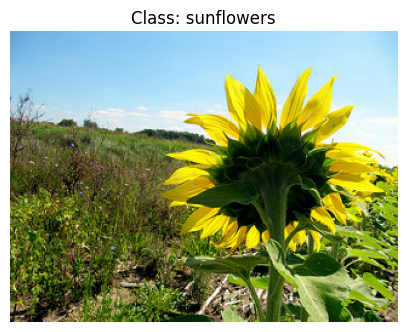

Original Image Shape: (240, 320, 3)
Preprocessed Image Shape: (150, 150, 3)


In [13]:
img, label = next(iter(train_raw.skip(2).take(1)))

plt.figure(figsize=(5, 5))
plt.imshow(img.numpy())

plt.title(f"Class: {class_names[int(label)]}")
plt.axis("off")
plt.show()

print("Original Image Shape:", img.shape)

processed_img, processed_label = prep(img, label)

print("Preprocessed Image Shape:", processed_img.shape)

## a. Load the pre-trained VGG16 model
`include_top=False` removes the original ImageNet classifier

In [14]:
base_model = VGG16(weights="imagenet", include_top=False,
                   input_shape=(IMG_SIZE, IMG_SIZE, 3))

## b. Freeze the convolutional layers

In [15]:
base_model.trainable = False

## c. Add a custom classifier

In [16]:
model = models.Sequential([
    base_model,
    layers.Flatten(),
    layers.Dense(50, activation="relu"),
    layers.Dense(20, activation="relu"),
    layers.Dense(5, activation="softmax")
])

model.compile(optimizer="adam",
              loss="categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 50)             │       409,650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │         1,020 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           105 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,125,463 (57.70 MB)

 Trainable params: 410,775 (1.57 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

## d. Train the classifier

In [17]:
history = model.fit(train_ds, validation_data=val_ds, epochs=2)

Epoch 1/2
81/81 ━━━━━━━━━━━━━━━━━━━━ 102s 1s/step - accuracy: 0.5562 - loss: 1.4591 - val_accuracy: 0.6661 - val_loss: 0.8619
Epoch 2/2
81/81 ━━━━━━━━━━━━━━━━━━━━ 101s 1s/step - accuracy: 0.7528 - loss: 0.6856 - val_accuracy: 0.7514 - val_loss: 0.7677


## e. Unfreeze the last VGG16 block and fine-tune

In [18]:
base_model.trainable = True
for layer in base_model.layers:
    layer.trainable = layer.name.startswith("block5")

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="categorical_crossentropy",
              metrics=["accuracy"])

fine_history = model.fit(train_ds, validation_data=val_ds, epochs=2)

Epoch 1/2


81/81 ━━━━━━━━━━━━━━━━━━━━ 120s 1s/step - accuracy: 0.8427 - loss: 0.4386 - val_accuracy: 0.7659 - val_loss: 0.6725
Epoch 2/2
81/81 ━━━━━━━━━━━━━━━━━━━━ 127s 2s/step - accuracy: 0.8786 - loss: 0.3037 - val_accuracy: 0.7895 - val_loss: 0.7541


## Plot accuracy

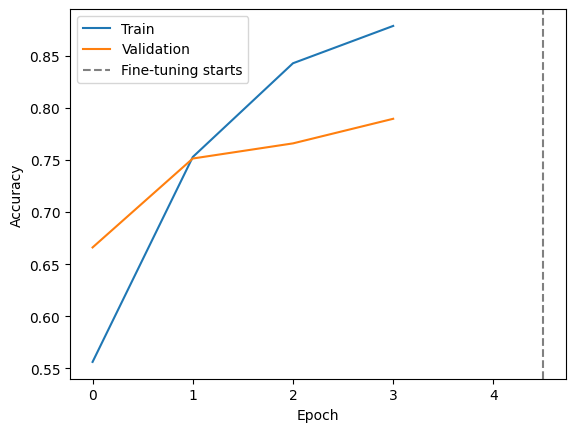

In [19]:
acc = history.history["accuracy"] + fine_history.history["accuracy"]
val_acc = history.history["val_accuracy"] + fine_history.history["val_accuracy"]

plt.plot(acc, label="Train")
plt.plot(val_acc, label="Validation")
plt.axvline(4.5, color="gray", linestyle="--", label="Fine-tuning starts")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

## Evaluate on the test set

In [20]:
loss, accuracy = model.evaluate(test_ds)
print("Test accuracy:", round(accuracy * 100, 2), "%")

18/18 ━━━━━━━━━━━━━━━━━━━━ 17s 935ms/step - accuracy: 0.7909 - loss: 0.7663
Test accuracy: 79.09 %


## Predict one test image

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 248ms/step


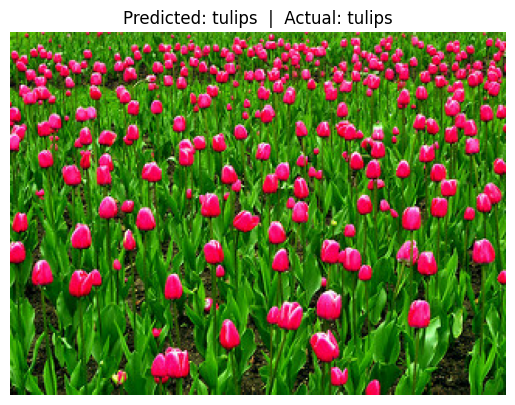

In [21]:
img, label = next(iter(test_raw.skip(10).take(1)))

x, _ = prep(img, label)
pred = model.predict(tf.expand_dims(x, 0))

plt.imshow(img.numpy())
plt.title(f"Predicted: {class_names[np.argmax(pred)]}  |  Actual: {class_names[int(label)]}")
plt.axis("off")
plt.show()

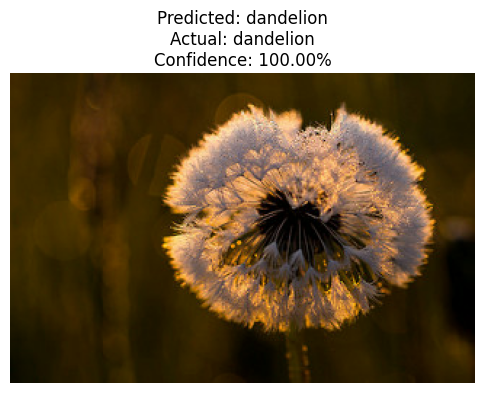

In [23]:
img, label = next(iter(test_raw.skip(11).take(1)))

x, _ = prep(img, label)

pred = model.predict(
    tf.expand_dims(x, 0),
    verbose=0
)

predicted_index = np.argmax(pred[0])

confidence = pred[0][predicted_index] * 100

# Display image
plt.figure(figsize=(6, 5))
plt.imshow(img.numpy())

plt.title(
    f"Predicted: {class_names[predicted_index]}\n"
    f"Actual: {class_names[int(label)]}\n"
    f"Confidence: {confidence:.2f}%"
)

plt.axis("off")
plt.show()